# 2.4 Prompt engineering: clear, specific, XML tags, examples

Step 2, lesson 4 of [Building with the Claude API](https://anthropic.skilljar.com/claude-with-the-anthropic-api/287745) (Anthropic Academy).
Exam domain: **4 Prompt Engineering & Structured Output**.

The course takes one weak prompt and improves it one technique at a time, measuring each version with the eval pipeline from [2.3](03-prompt-evaluation.ipynb). Same here, in the course's order:

1. Baseline: a vague prompt
2. Being clear and direct
3. Being specific: guidelines and steps
4. Structuring the prompt with XML tags
5. Giving examples (one-shot / multi-shot)
6. Beyond the course: a guideline aimed at what the grader keeps finding
7. Comparing the scores

The task, as in the course: **a one-day meal plan for an athlete**, given height, weight, goal and dietary restrictions.

> **Model used here:** `claude-sonnet-5-5`.
>
> **Cost:** 1 request for the dataset, then 3 test cases × 2 requests (answer + grade) for each of the 6 prompt versions: 37 requests.

In [1]:
import json
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt
from anthropic import Anthropic
from dotenv import load_dotenv
from pydantic import BaseModel, Field

load_dotenv()
client = Anthropic()
model = "claude-sonnet-5-5"

OUTPUTS = Path("outputs")
OUTPUTS.mkdir(exist_ok=True)


def text_of(message):
    """Return the text of the first text block in a response ("" if there is none)."""
    return next((block.text for block in message.content if block.type == "text"), "")


def chat(messages, system=None, max_tokens=1000, effort="low"):
    params = {"model": model, "max_tokens": max_tokens, "messages": messages, "output_config": {"effort": effort}}
    if system:
        params["system"] = system
    return text_of(client.messages.create(**params))

## The eval pipeline, compact

The same steps as 2.3, folded into a few functions:

- a **dataset** of athletes generated by Claude, each with its own solution criteria;
- **extra criteria** that apply to every case (what any good meal plan must contain);
- a **model grader** that returns a 1–10 score as structured output;
- `evaluate(build_prompt, label)`, which runs one prompt version over the whole dataset and records its average.

There's no code grader this time: a meal plan has no syntax to check.

In [2]:
class Athlete(BaseModel):
    height: str = Field(description="for example '180 cm'")
    weight: str = Field(description="for example '75 kg'")
    goal: str
    restrictions: str = Field(description="dietary restrictions, or 'none'")
    solution_criteria: list[str] = Field(description="2 to 4 checks a good meal plan for this athlete must pass")


class AthleteDataset(BaseModel):
    cases: list[Athlete]


response = client.messages.parse(
    model=model,
    max_tokens=2000,
    output_config={"effort": "low"},
    messages=[{"role": "user", "content": (
        "Write 3 varied test cases for a prompt that writes a one-day meal plan for an athlete. "
        "Vary the sport, the goal (gain, lose or maintain weight; performance) and the dietary restrictions "
        "(include at least one strict restriction such as vegan or a food allergy)."
    )}],
    output_format=AthleteDataset,
)
dataset = response.parsed_output.cases
for i, a in enumerate(dataset, 1):
    print(f"{i}. {a.height}, {a.weight} | goal: {a.goal} | restrictions: {a.restrictions}")
    for c in a.solution_criteria:
        print("     -", c)

1. 183 cm, 78 kg | goal: Gain lean muscle mass during an off-season strength block for rugby, aiming for about 0.4 kg gain per week | restrictions: vegan
     - Contains no animal products (no meat, fish, dairy, eggs, honey, or gelatin)
     - Provides a calorie surplus of roughly 300-500 kcal above maintenance (about 3,200-3,500 kcal total)
     - Provides at least 1.6-2.0 g of protein per kg body weight (about 125-155 g) from varied plant sources
     - Includes a protein-rich meal or snack within a couple of hours after training
2. 165 cm, 62 kg | goal: Lose about 3 kg of body fat over 8 weeks while maintaining training quality for distance running (50 km per week) | restrictions: severe peanut and tree nut allergy
     - Contains no peanuts, tree nuts, or foods likely to include them (e.g., pesto, granola bars, nut butters)
     - Uses a moderate calorie deficit of about 300-500 kcal below maintenance without dropping below roughly 1,900 kcal
     - Provides adequate carbohydrates 

In [3]:
EXTRA_CRITERIA = """Every meal plan must include:
- the total daily calories
- grams of protein, fat and carbohydrates for the day
- specific foods with portion sizes
- when to eat each meal and snack"""


class Grade(BaseModel):
    strengths: list[str]
    weaknesses: list[str]
    reasoning: str
    score: int = Field(description="1 to 10")


def grade(athlete, output):
    criteria = "\n".join(f"- {c}" for c in athlete.solution_criteria)
    prompt = f"""You are an expert sports nutritionist reviewing an AI-generated one-day meal plan.

<athlete>
Height: {athlete.height}
Weight: {athlete.weight}
Goal: {athlete.goal}
Dietary restrictions: {athlete.restrictions}
</athlete>

<meal_plan>
{output}
</meal_plan>

<criteria>
{criteria}
{EXTRA_CRITERIA}
</criteria>

Score the meal plan from 1 to 10:
- 10: meets every criterion, accurate and practical
- 7-9: meets every criterion, with minor issues
- 4-6: misses one criterion, or has a notable error
- 1-3: misses several criteria, or breaks a dietary restriction
A plan that misses any criterion cannot score above 6."""
    response = client.messages.parse(
        model=model,
        max_tokens=2000,
        output_config={"effort": "medium"},
        messages=[{"role": "user", "content": prompt}],
        output_format=Grade,
    )
    return response.parsed_output


scores = {}      # label -> average score
all_results = {} # label -> per-case results


def evaluate(build_prompt, label, show_output=False):
    results = []
    for athlete in dataset:
        output = chat([{"role": "user", "content": build_prompt(athlete)}], max_tokens=4000)
        g = grade(athlete, output)
        results.append({"athlete": athlete.model_dump(), "output": output, **g.model_dump()})
    scores[label] = mean(r["score"] for r in results)
    all_results[label] = results
    (OUTPUTS / "04-eval-results.json").write_text(json.dumps(all_results, indent=2))

    print(f"{label}: scores {[r['score'] for r in results]} -> average {scores[label]:.2f} / 10")
    worst = min(results, key=lambda r: r["score"])
    print("Weaknesses of the lowest-scoring plan:")
    for w in worst["weaknesses"][:3]:
        print("  -", w)
    if show_output:
        print("\n--- first output (start) ---\n" + results[0]["output"][:900])

## 1. Baseline

A first draft, written the way people often start: a question, and the data.

In [4]:
def prompt_v1(a):
    return f"""What should this person eat?

- Height: {a.height}
- Weight: {a.weight}
- Goal: {a.goal}
- Dietary restrictions: {a.restrictions}"""


evaluate(prompt_v1, "1 baseline", show_output=True)

1 baseline: scores [4, 5, 4] -> average 4.33 / 10
Weaknesses of the lowest-scoring plan:
  - No timing is given for most meals and snacks (no clock times or relative times other than 'pre-training' and 'post-training'), which fails the required 'when to eat' element
  - Daily totals for fat and carbohydrate are not stated for the sample day; only target ranges are given, so the required daily grams of protein, fat, and carbs are incomplete
  - Meal calorie figures sum to ~3,800 kcal (900+850+400+500+850+300), not the claimed ~3,350, and protein sums to 200 g rather than 150 g, so the numbers are internally inconsistent

--- first output (start) ---
# Vegan Lean-Gain Plan: 183 cm, 78 kg Rugby Player (Off-Season)

## Targets
Estimated maintenance for a trained, active rugby player is about 3,000 kcal. A 0.4 kg/week gain needs a surplus of roughly 300-400 kcal/day.

| Nutrient | Daily target | Notes |
|---|---|---|
| **Calories** | **~3,300-3,400 kcal** | Adjust by ±150 kcal every 2 weeks

## 2. Being clear and direct

The first line of a prompt carries the most weight. Make it an **instruction with an action verb** that names the task and the result you want ("Generate a one-day meal plan..."), not a question Claude has to interpret. Imagine the prompt going to a capable colleague who knows nothing about your project: would they know exactly what to produce?

In [5]:
def prompt_v2(a):
    return f"""Generate a one-day meal plan for an athlete that meets their dietary restrictions.

- Height: {a.height}
- Weight: {a.weight}
- Goal: {a.goal}
- Dietary restrictions: {a.restrictions}"""


evaluate(prompt_v2, "2 clear and direct")

2 clear and direct: scores [5, 6, 5] -> average 5.33 / 10
Weaknesses of the lowest-scoring plan:
  - The plan as listed totals ~4,100 kcal by its own admission, well above the 3,300 target and the 3,200-3,500 range; the user must scale it back themselves, so it is not a ready-to-use plan
  - Meal calorie figures sum to roughly 4,100, so the final totals are inconsistent with the stated targets; the plan gives a range for macros (carbs 430-480 g, fat 95-110 g) rather than a firm figure for the adjusted plan
  - Protein listed per meal sums to ~200 g, yet the total claims ~160 g, which is inconsistent


## 3. Being specific

Clear says *what* to do; specific says *what a good result looks like*. The course describes two kinds of specifics:

- **Guidelines** about the output: qualities it must have (length, sections, units, what to include). Almost every prompt benefits from these.
- **Steps** for Claude to follow before answering, for harder problems where you want it to consider things in a set order (e.g. "first estimate energy needs, then split them across meals").

Version 3 adds guidelines that mirror what the grader checks. That's the point of writing criteria down: the prompt and the eval ask for the same things.

In [6]:
def prompt_v3(a):
    return f"""Generate a one-day meal plan for an athlete that meets their dietary restrictions.

- Height: {a.height}
- Weight: {a.weight}
- Goal: {a.goal}
- Dietary restrictions: {a.restrictions}

Guidelines:
1. State the total daily calories, and how you estimated them from the athlete's size and goal.
2. Give grams of protein, fat and carbohydrates for the day.
3. Give a time for every meal and snack.
4. Use only foods that respect the dietary restrictions.
5. List every food with a portion size (grams, millilitres or common units).
6. Keep it practical: everyday foods, short preparation."""


evaluate(prompt_v3, "3 specific")

3 specific: scores [8, 5, 7] -> average 6.67 / 10
Weaknesses of the lowest-scoring plan:
  - Target of about 1,800 kcal falls below the roughly 1,900 kcal floor in the criteria
  - Estimated TDEE of 2,200 kcal is built on assumed sex and age, which the athlete did not provide
  - Macro table is inconsistent: 125 g protein is 500 kcal, 250 g carbohydrate is 1,000 kcal, and 33 g fat is 300 kcal, totaling 1,800 kcal, but the sums are not fully verified against the foods listed


## 4. Structuring with XML tags

When a prompt mixes instructions with data, **XML tags** mark where each piece starts and ends: `<athlete_information>...</athlete_information>`. Claude doesn't need special tag names; descriptive ones work best. Tags matter most when the data is long (a document, a table of records, a code file) and could otherwise be mistaken for instructions. Here the data is four short lines, so expect a small effect.

In [7]:
def prompt_v4(a):
    return f"""Generate a one-day meal plan for an athlete that meets their dietary restrictions.

<athlete_information>
- Height: {a.height}
- Weight: {a.weight}
- Goal: {a.goal}
- Dietary restrictions: {a.restrictions}
</athlete_information>

<guidelines>
1. State the total daily calories, and how you estimated them from the athlete's size and goal.
2. Give grams of protein, fat and carbohydrates for the day.
3. Give a time for every meal and snack.
4. Use only foods that respect the dietary restrictions.
5. List every food with a portion size (grams, millilitres or common units).
6. Keep it practical: everyday foods, short preparation.
</guidelines>"""


evaluate(prompt_v4, "4 XML tags")

4 XML tags: scores [8, 4, 6] -> average 6.00 / 10
Weaknesses of the lowest-scoring plan:
  - The 1,800 kcal target is below the roughly 1,900 kcal floor in the criteria, so it misses a stated criterion
  - The stated deficit of 350-400 kcal from a 2,150 kcal maintenance would give about 1,750-1,800 kcal; the plan relies on assumed sex and age, which makes the maintenance figure uncertain
  - Macro table is internally inconsistent: 110 g protein, 250 g carbs and 62 g fat sum to about 2,000 kcal, not 1,800, and the percentages total over 100% (24+56+31); the plan waves this off as rounding


## 5. Giving examples

An example shows the format and level of detail better than any description. One example is **one-shot**, several are **multi-shot** (few-shot). Practices from the course:

- wrap each example in tags (`<sample_input>`, `<ideal_output>`) so it isn't confused with the real input;
- say **why** the example is good, so Claude copies the right things;
- pick examples for the cases that go wrong (edge cases), not only easy ones;
- use an input that differs from the real ones, so Claude copies the format, not the content.

The example below is a hand-written plan for an athlete who is not in the dataset.

In [8]:
EXAMPLE = """<sample_input>
- Height: 165 cm
- Weight: 58 kg
- Goal: maintain weight while training for a half marathon
- Dietary restrictions: vegetarian
</sample_input>

<ideal_output>
Daily target: about 2,300 kcal (maintenance for a 58 kg runner who trains most days)
Macros: protein 105 g, carbohydrates 330 g, fat 65 g

07:00 Breakfast (about 600 kcal): 80 g rolled oats cooked in 250 ml semi-skimmed milk, 1 banana (120 g), 15 g peanut butter
10:30 Snack (about 250 kcal): 170 g Greek yogurt, 100 g blueberries, 10 g honey
13:00 Lunch (about 650 kcal): 2 wholemeal wraps, 120 g hummus, 100 g falafel, 100 g mixed salad, 150 ml orange juice
16:30 Pre-run snack (about 200 kcal): 2 rice cakes with 20 g jam, 1 apple
19:30 Dinner (about 600 kcal): 100 g dry wholewheat pasta, 150 g firm tofu, 200 g tomato and vegetable sauce, 15 g olive oil, 20 g parmesan
</ideal_output>

<why_this_is_good>
It states the calorie target with a one-line reason, gives the macros in grams, times every meal,
gives a portion for every food, respects the restriction, and stays short enough to stick on a fridge.
</why_this_is_good>"""


def prompt_v5(a):
    return f"""Generate a one-day meal plan for an athlete that meets their dietary restrictions.

<athlete_information>
- Height: {a.height}
- Weight: {a.weight}
- Goal: {a.goal}
- Dietary restrictions: {a.restrictions}
</athlete_information>

<guidelines>
1. State the total daily calories, and how you estimated them from the athlete's size and goal.
2. Give grams of protein, fat and carbohydrates for the day.
3. Give a time for every meal and snack.
4. Use only foods that respect the dietary restrictions.
5. List every food with a portion size (grams, millilitres or common units).
6. Keep it practical: everyday foods, short preparation.
</guidelines>

Here is an example of a good plan for a different athlete. Follow its format and level of detail.

<example>
{EXAMPLE}
</example>"""


evaluate(prompt_v5, "5 examples", show_output=True)

5 examples: scores [5, 6, 6] -> average 5.67 / 10
Weaknesses of the lowest-scoring plan:
  - Meal calorie estimates sum to about 3,600 kcal (800+450+850+400+800+300), not the stated 3,300, so the plan is internally inconsistent
  - Macros do not reconcile: 150 g protein x4 + 460 g carbs x4 + 90 g fat x9 is about 3,250 kcal, which differs from the meal-level sums
  - Itemised foods likely supply well under 150 g protein (roughly 110-130 g), so the stated protein is probably overstated

--- first output (start) ---
Daily target: about 3,300 kcal (estimated maintenance of roughly 3,000 kcal for a 78 kg rugby player in heavy strength training, about 38-39 kcal/kg, plus about 300 kcal surplus for ~0.4 kg/week gain)
Macros: protein 150 g, carbohydrates 460 g, fat 90 g

07:00 Breakfast (about 800 kcal): 100 g rolled oats cooked in 300 ml soy milk, 1 banana (120 g), 30 g peanut butter, 20 g ground flaxseed, 15 g maple syrup

10:30 Snack (about 450 kcal): 1 vegan protein shake (30 g pea/soy pro

## 6. Beyond the course: target what the grader keeps finding

> **Beyond the course.** The course stops at examples. But the grader's notes above point at the same weakness in almost every version: **the numbers don't add up** (meal calories that sum to more than the stated total, macros that don't match the calories). None of the techniques so far asked for that. The eval exists to find the actual failure, so version 6 adds one guideline aimed at it, and nothing else.

In [9]:
CHECK_GUIDELINE = """7. Make the numbers add up: the meal calories must sum to the daily total, and
   protein x 4 + carbohydrates x 4 + fat x 9 must be within 5% of it. Check this before you answer,
   and end with one line showing the sum."""


def prompt_v6(a):
    return prompt_v5(a).replace("6. Keep it practical: everyday foods, short preparation.",
                                "6. Keep it practical: everyday foods, short preparation.\n" + CHECK_GUIDELINE)


p = prompt_v6(dataset[0])
print(p[p.index("<guidelines>"):p.index("</guidelines>") + len("</guidelines>")])

<guidelines>
1. State the total daily calories, and how you estimated them from the athlete's size and goal.
2. Give grams of protein, fat and carbohydrates for the day.
3. Give a time for every meal and snack.
4. Use only foods that respect the dietary restrictions.
5. List every food with a portion size (grams, millilitres or common units).
6. Keep it practical: everyday foods, short preparation.
7. Make the numbers add up: the meal calories must sum to the daily total, and
   protein x 4 + carbohydrates x 4 + fat x 9 must be within 5% of it. Check this before you answer,
   and end with one line showing the sum.
</guidelines>


In [10]:
evaluate(prompt_v6, "6 targeted fix")

6 targeted fix: scores [4, 4, 3] -> average 3.67 / 10
Weaknesses of the lowest-scoring plan:
  - The listed foods cannot supply 616 g of carbohydrate. Rough totals are about 400-450 g, so the claimed macros do not match the actual meals
  - The per-meal calories look wrong. For example, the recovery lunch (60 g rice, chicken, vegetables, juice) is about 600 kcal, but it is not nearly enough carbohydrate for recovery, and the dinner pasta portion is small for the stated goal
  - In-race carbohydrate is roughly 100-120 g over 3 hours, or about 35-40 g/h. That is well under the 60-90 g/h criterion, and the plan never states a g/h target


## 7. Comparing the versions

1 baseline            4.33 / 10
2 clear and direct    5.33 / 10
3 specific            6.67 / 10
4 XML tags            6.00 / 10
5 examples            5.67 / 10
6 targeted fix        3.67 / 10

Average answer length (characters): {'1 baseline': 3598, '2 clear and direct': 3274, '3 specific': 3370, '4 XML tags': 3236, '5 examples': 1688, '6 targeted fix': 1263}


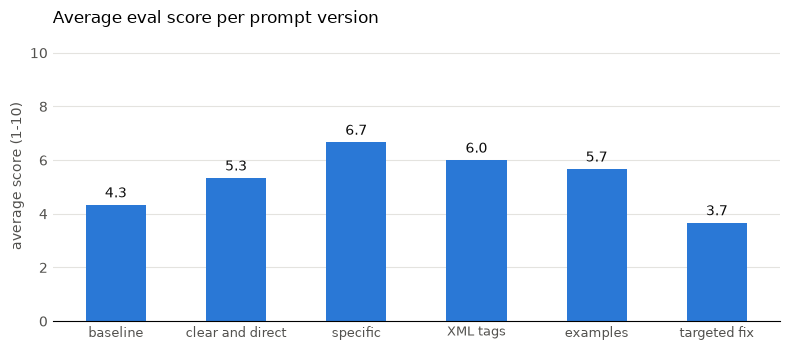

In [11]:
labels = list(scores)
values = [scores[k] for k in labels]
for k, v in zip(labels, values):
    print(f"{k:<20} {v:5.2f} / 10")

lengths = {k: mean(len(r["output"]) for r in all_results[k]) for k in labels}
print("\nAverage answer length (characters):", {k: round(v) for k, v in lengths.items()})

fig, ax = plt.subplots(figsize=(8, 3.6))
display_labels = [k.split(" ", 1)[1] for k in labels]   # drop the version number
bars = ax.bar(display_labels, values, width=0.5, color="#2a78d6")
ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], padding=3, color="#0b0b0b", fontsize=10)
ax.set_ylim(0, 10.8)
ax.set_ylabel("average score (1-10)", color="#52514e")
ax.set_title("Average eval score per prompt version", loc="left", fontsize=12)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors="#52514e", length=0)
plt.xticks(fontsize=9)
plt.tight_layout()
plt.show()

**What happened in this run.**

- **Clear and direct** (+1.0) and above all **specific guidelines** (+1.3 more) made the gains. The baseline plans left out meal times and full macro totals, which the grader requires; once the guidelines named them, they appeared.
- **XML tags** (6.0) and the **example** (5.7) added nothing measurable here. With four short lines of data, tags have little to separate, and a drop of half a point to a point on 3 cases is within the noise. The example did change the *format*: answers became half as long, with every meal timed and portioned like the sample.
- The **targeted fix made things worse** (3.7). The plans now end with a "check" line whose sums agree, but the grader points out that the check only adds up the plan's *own* numbers: the listed foods still don't supply the stated calories and macros. Asking the model to verify itself bought consistency, not accuracy. And the shorter plans dropped things some cases asked for (electrolytes, carbohydrate per hour during a race).

**What to take from it.**

1. A change that sounds right can lower the score. That's why each version is measured, not assumed.
2. Some failures aren't prompt problems. Nutrient arithmetic needs data: the proportionate fix is to compute the totals **in code** from a food table (for example a tool Claude calls, lessons 2.5–2.6), not more instructions. The grader has the same limit: a model estimating calories is itself approximate; a code check against a food database would be exact.
3. 3 cases, one run each, is a demo. A real eval uses many more cases and repeats runs before trusting a difference of a point.

**Exam angle (Domain 4).**

- **Explicit criteria beat vague instructions.** "Be thorough" or "be conservative" changes little; listing exactly what to include (or what counts as a problem worth reporting) changes a lot. The same goes for review prompts: say which issues to report and which to skip, to cut false positives.
- **Few-shot examples** are the go-to fix when the output format or judgement is inconsistent, especially for ambiguous cases. Show the edge case, and explain the reasoning behind the example.
- **XML tags** separate instructions from data, and help most with long inputs.
- **When something must be right every time, enforce it in code.** A model checking its own output in the same pass shares its own blind spots (version 6). Calculations, totals and hard rules belong in code; judgement calls can go to an independent reviewer (a separate call or instance), not the same pass.
- **Measure before and after.** A prompt change is kept because the eval score went up, not because it reads better.

## Recap

- Baseline → clear and direct (action verb, first line) → specific (guidelines, steps) → XML tags → examples, each scored with the 2.3 pipeline.
- Here the specific guidelines did most of the work; tags and an example changed little for a short, simple input.
- Read the grader's weaknesses to find the real failure; a prompt-only "check your numbers" made consistency, not correctness. Move calculations into code.
- Write the grader's criteria and the prompt's guidelines from the same list.

Results are saved in `outputs/04-eval-results.json` (not committed).

Next: [2.5 Tool use basics](05-tool-use-basics.ipynb).